# Temporal features in the LION-intersection KSI model

Tested whether nighttime and weekend crash shares and recent changes in crash counts improve Claire’s KSI v2 model. Also included a no-history control to check whether the temporal features provide additional value.

Following Claire’s setup, the models train on 2022 outcomes and predict total KSI crashes for 2023–2025 using history available before 2023. This experiment uses LION release 26c, which may include road changes made after the study years.


## 1. Setup and required files

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FEI = ROOT / "Fei" if (ROOT / "Fei").exists() else ROOT / "fei"
BASELINE = FEI / "local" / "ksi_v2_baseline"
LION_PATH = FEI / "local" / "lion_26c" / "lion" / "lion.gdb"
OUTPUT = FEI / "outputs" / "ksi_v2_temporal_features"
assert (BASELINE / "preprocessing/panel.py").exists(), "Prepare the pinned v2 code described above."
for package in ("preprocessing", "model", "validation", "data"):
    loaded = sys.modules.get(package)
    paths = list(getattr(loaded, "__path__", [])) if loaded else []
    if paths and not all(Path(p).resolve().is_relative_to(BASELINE.resolve()) for p in paths):
        raise RuntimeError("Restart the kernel: another team code version is already imported.")
sys.path.insert(0, str(FEI))
sys.path.insert(0, str(BASELINE))
import data.reader as reader
reader.LION_PATH = LION_PATH
from preprocessing.config import SiteConfig, PanelConfig
from preprocessing.panel import load_panel
from preprocessing.crashes import load_crashes
from preprocessing.sites import project_coordinates, assign_nearest_site
from preprocessing.roadway import ROADWAY_FEATURES, load_roadway_features, add_roadway_features
from model.count_models import NegativeBinomialModel
from validation.validate import pooled_holdout, calibration_table, ValidationConfig
from temporal_features import temporal_features, select_features, FEATURE_GROUPS
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

if not LION_PATH.exists():
    raise FileNotFoundError(f"Missing LION geodatabase: {LION_PATH}. Use Claire's release and update LION_PATH.")
raw = BASELINE / "data/raw"
for name in ("crashes.parquet", "persons.parquet", "vehicles.parquet"):
    if not (raw / name).exists():
        raise FileNotFoundError(f"Missing {name}; download the crash cache first.")
cloud_only = [str(p) for folder in (raw, LION_PATH) for p in folder.rglob("*")
              if p.is_file() and getattr(p.stat(), "st_flags", 0) & 0x40000000]
if cloud_only:
    raise RuntimeError(f"Download iCloud placeholders before running: {cloud_only[:10]}")
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Baseline code:", (BASELINE / "SOURCE_COMMIT.txt").read_text().strip()[:7])
print("LION release: 26c")

Baseline code: 019e40c
LION release: 26c


## 2. Reuse Claire's panel and LION sites

Vehicles are needed for the crash-type features. The same nearest-site function assigns crashes to LION intersections within 100 ft. Historical counts must agree with the baseline before fitting.

In [2]:
site_config, panel_config = SiteConfig(source="lion"), PanelConfig()
panel, scoring, sites = load_panel(site_config=site_config, config=panel_config)
roadway = load_roadway_features(sites, site_config=site_config)
panel = add_roadway_features(panel, roadway)
crashes = assign_nearest_site(project_coordinates(load_crashes(), site_config), sites, site_config)
times = reader.read_table("crashes", ["collision_id", "crash_time"])
times["collision_id"] = pd.to_numeric(times.collision_id, errors="raise").astype("int64")
assert times.collision_id.is_unique
crashes = crashes.merge(times, on="collision_id", how="left", validate="one_to_one")
print(f"{len(sites):,} LION sites; {len(panel):,} site-year rows")
print("Claire's saved notebook reports 46,896 sites. Investigate differences before comparing results.")
display(panel.groupby("year")[["ksi", "rlr", "rear_end", "angle", "crashes"]].sum())

46,896 LION sites; 187,584 site-year rows
Claire's saved notebook reports 46,896 sites. Investigate differences before comparing results.


,ksi,rlr,rear_end,angle,crashes
year,,,,,
2022,2085,2741,15243,16199,69149
2023,2222,2898,14524,15747,66063
2024,2208,2501,13452,13961,61066
2025,2180,2186,13010,12882,57833


## 3. Build temporal features

Night = 22:00–05:59; weekend = Saturday/Sunday. Shares pool the preceding three years. Recent change compares the previous year with the mean of the two earlier years using log(1 + count). Missing times and absent history are flagged. These are crash shares, not exposure-adjusted risk rates.

In [3]:
features = temporal_features(crashes, sites.site_id, panel_config.first_year, panel_config.last_year)
temporal_columns = list(dict.fromkeys(f for group in FEATURE_GROUPS.values() for f in group))
experiment = panel.merge(features[["site_id", "year", "total_lag3", *temporal_columns]],
                         on=["site_id", "year"], validate="one_to_one")
assert len(experiment) == len(panel)
assert np.allclose(experiment.total_lag3, experiment.crashes_lag3)
assert set(experiment.year) == {2022, 2023, 2024, 2025}
assert np.isfinite(experiment[temporal_columns].to_numpy(dtype=float)).all()
quality = experiment.groupby("year")[["no_history", "night_unavailable", "unknown_time_share_lag3"]].mean()
display(quality)
quality.to_csv(OUTPUT / "feature_quality.csv")

,no_history,night_unavailable,unknown_time_share_lag3
year,,,
2022,0.265140,0.265140,0.0
2023,0.296934,0.296934,0.0
2024,0.309408,0.309408,0.0
2025,0.321563,0.321563,0.0


## 4. Compare models using the same pooled holdout

Train only on 2022. The primary baseline is Claire's full model (history + crash types + roads); Q1 is included as a reproduction check. Every temporal variant also includes no_history. Constant/identical columns are selected using training rows only. The pooled test is exploratory because it has already been inspected by the team.

In [4]:
HISTORY = [f"log1p_{c}_lag3" for c in ["pdo", "injury_nonsevere", "ksi_nonfatal", "fatal", "ped_injured", "cyc_injured"]]
TYPES = [f"log1p_{c}_lag3" for c in ["rlr", "rear_end", "angle"]]
ROAD = [f for f in ROADWAY_FEATURES if f != "legs_3"]
BASE = HISTORY + TYPES + ROAD
CONTROL = "Full + no_history"
specs = {"Q1 history": HISTORY, "Full baseline": BASE, CONTROL: BASE + ["no_history"]}
for name, group in FEATURE_GROUPS.items():
    specs["+ " + name] = list(dict.fromkeys(BASE + ["no_history"] + group))
specs["+ All temporal"] = list(dict.fromkeys(BASE + ["no_history"] + temporal_columns))
train = experiment[experiment.year < 2023]
assert set(train.year) == {2022}
results, calibrations, omitted = [], [], []
for name, requested in specs.items():
    used, dropped = select_features(train, requested)
    print("Fitting", name, "| omitted:", dropped, flush=True)
    fitted = []
    def make_model():
        model = NegativeBinomialModel(used)
        fitted.append(model)
        return model
    metrics, totals = pooled_holdout(make_model, experiment, (2023, 2024, 2025), (100, 1000))
    if not fitted[0].result_.mle_retvals.get("converged", False):
        raise RuntimeError(f"{name} did not converge; do not interpret its scores.")
    assert np.isfinite(totals.pred).all() and totals.pred.ge(0).all()
    results.append({"model": name,
        "top_100": metrics.loc[(metrics.metric == "capture") & (metrics.k == 100), "value"].iloc[0],
        "top_1000": metrics.loc[(metrics.metric == "capture") & (metrics.k == 1000), "value"].iloc[0],
        "deviance": metrics.loc[metrics.metric == "deviance", "value"].iloc[0],
        "observed_predicted_ratio": totals.ksi.sum() / totals.pred.sum()})
    cal = calibration_table(totals.ksi, totals.pred, ValidationConfig().calibration_quantiles)
    calibrations.append(cal.reset_index().assign(model=name))
    omitted.append({"model": name, "omitted": str(dropped)})
results = pd.DataFrame(results)
calibration = pd.concat(calibrations, ignore_index=True)
results.to_csv(OUTPUT / "pooled_model_comparison.csv", index=False)
calibration.to_csv(OUTPUT / "pooled_calibration.csv", index=False)
pd.DataFrame(omitted).to_csv(OUTPUT / "omitted_features.csv", index=False)
display(results.round(4))
print("Reference notebook: Q1 capture1000 = 0.1790; full = 0.1805. These are reproduction checks, not targets.")

Fitting Q1 history | omitted: {}


Fitting Full baseline | omitted: {}


Fitting Full + no_history | omitted: {}


Fitting + Nighttime | omitted: {'unknown_time_share_lag3': 'constant in training data', 'night_unavailable': 'identical to no_history in training data'}


Fitting + Weekend | omitted: {}


Fitting + Recent change | omitted: {}


Fitting + All temporal | omitted: {'unknown_time_share_lag3': 'constant in training data', 'night_unavailable': 'identical to no_history in training data'}


,model,top_100,top_1000,deviance,observed_predicted_ratio
0,Q1 history,0.0312,0.1790,0.4672,1.3205
1,Full baseline,0.0306,0.1803,0.4564,1.2891
2,Full + no_history,0.0292,0.1806,0.4516,1.2683
3,+ Nighttime,0.0297,0.1802,0.4514,1.2608
4,+ Weekend,0.0292,0.1805,0.4517,1.2694
5,+ Recent change,0.0304,0.1825,0.4500,1.2127
6,+ All temporal,0.0306,0.1823,0.4500,1.2084


Reference notebook: Q1 capture1000 = 0.1790; full = 0.1805. These are reproduction checks, not targets.


## 5. Plot pooled ranking, count error and calibration

Capture should increase, deviance should decrease, and observed/predicted should approach 1. Compare temporal variants with the no-history control. These are three-year pooled metrics, not annual scores from the earlier notebook.

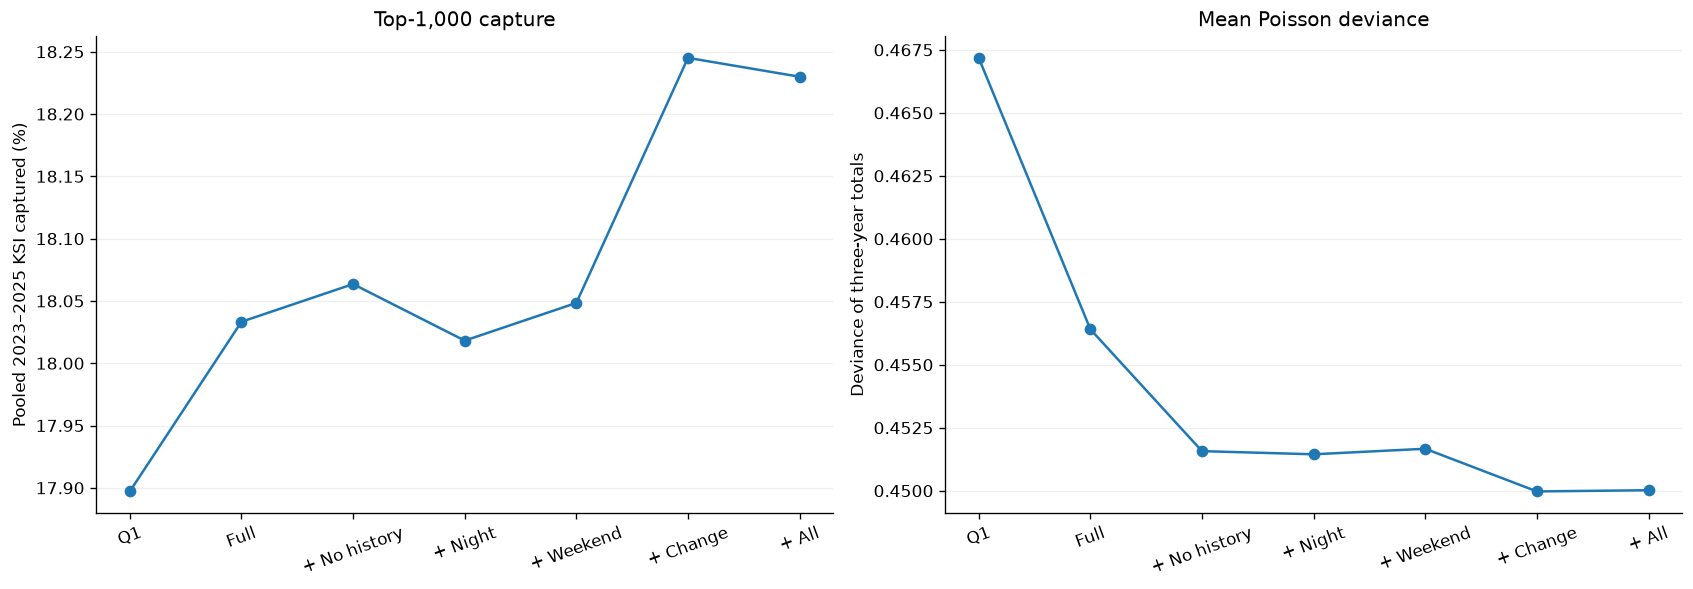

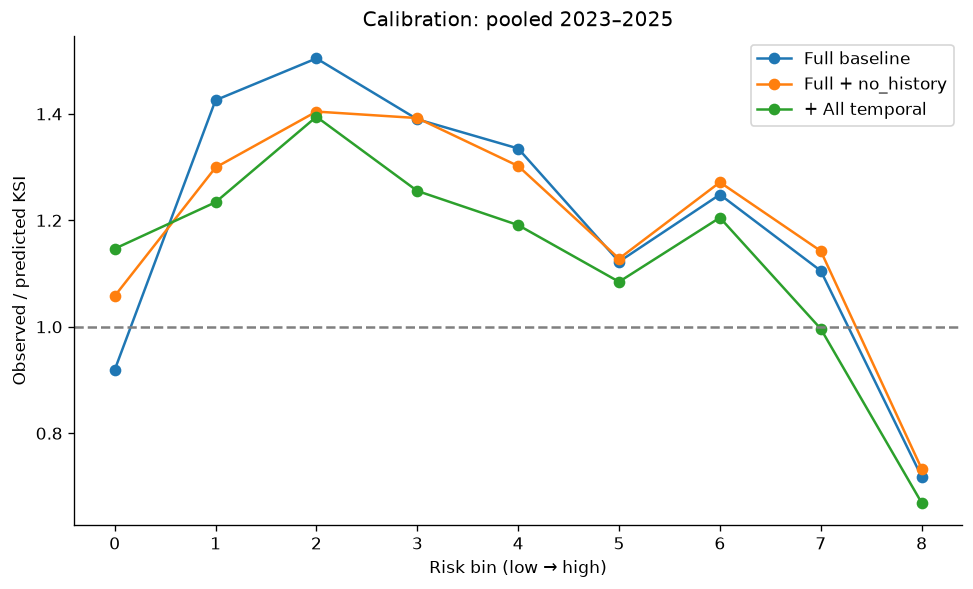

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout="constrained")
x = np.arange(len(results))
labels = ["Q1", "Full", "+ No history", "+ Night", "+ Weekend", "+ Change", "+ All"]
axes[0].plot(x, 100 * results.top_1000, marker="o")
axes[1].plot(x, results.deviance, marker="o")
axes[0].set(title="Top-1,000 capture", ylabel="Pooled 2023–2025 KSI captured (%)")
axes[1].set(title="Mean Poisson deviance", ylabel="Deviance of three-year totals")
for ax in axes:
    ax.set_xticks(x, labels, rotation=20)
    ax.grid(axis="y", alpha=.2)
fig.savefig(OUTPUT / "pooled_comparison.png", dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
for name in ["Full baseline", CONTROL, "+ All temporal"]:
    d = calibration[calibration.model == name].sort_values("bin")
    ax.plot(d.bin, d.obs_total / d.pred_total.replace(0, np.nan), marker="o", label=name)
ax.axhline(1, color="gray", linestyle="--")
ax.set(xlabel="Risk bin (low → high)", ylabel="Observed / predicted KSI", title="Calibration: pooled 2023–2025")
ax.legend()
fig.savefig(OUTPUT / "pooled_calibration.png", dpi=180)
plt.show()

## 6. Incremental value and limitations

A single pooled test cannot establish stable improvement or statistical significance. This reuses Claire's contemporary LION snapshot and road-feature imputation; it does not reconstruct historical road design. No traffic-exposure denominator is available. Predictions assume the estimated annual rate stays constant over the three-year window.

In [6]:
comparison = results.set_index("model").copy()
reference = comparison.loc[CONTROL]
comparison["capture_change_pp"] = 100 * (comparison.top_1000 - reference.top_1000)
comparison["deviance_change_pct"] = 100 * (comparison.deviance / reference.deviance - 1)
display(comparison[["capture_change_pp", "deviance_change_pct"]].round(4))
comparison.to_csv(OUTPUT / "comparison_against_no_history.csv")
print("No conclusion is assigned automatically: inspect reproduction checks, convergence and calibration first.")

,capture_change_pp,deviance_change_pct
model,,
Q1 history,-0.1664,3.4568
Full baseline,-0.0303,1.0713
Full + no_history,0.0000,0.0000
+ Nighttime,-0.0454,-0.0277
+ Weekend,-0.0151,0.0210
+ Recent change,0.1815,-0.3541
+ All temporal,0.1664,-0.3436


No conclusion is assigned automatically: inspect reproduction checks, convergence and calibration first.
